# 02 - Exploratory Data Analysis (EDA)
**Goal:** understand the data before modelling: its shape, quality, balance and which features matter.

**Dataset:** phishing-website features. Every feature is `-1` (suspicious), `0` (neutral) or `1` (legitimate).
**Target `Result`:** `-1` = phishing, `1` = legitimate.

> Only the **train** split is used here, so nothing is learned from the test set.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
DATA = Path("..") / "Artifacts" / "notebooks" / "train.csv"   # made by notebook 01
TARGET = "Result"
df = pd.read_csv(DATA)
features = [c for c in df.columns if c != TARGET]
print("rows, columns:", df.shape)
df.head()

rows, columns: (8844, 31)


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,1,-1,1,...,1,1,1,1,0,-1,1,0,1,-1
1,1,-1,1,1,1,-1,0,0,-1,-1,...,-1,1,1,1,0,-1,1,0,1,-1
2,1,-1,1,1,1,-1,1,1,1,1,...,1,1,-1,1,1,1,1,0,1,1
3,1,-1,1,1,1,1,1,1,-1,1,...,-1,1,-1,1,1,1,1,0,1,1
4,1,1,-1,-1,-1,1,1,-1,-1,1,...,1,1,1,-1,0,1,-1,1,1,1


## 1. Structure & data types

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8844 entries, 0 to 8843
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   having_IP_Address            8844 non-null   int64
 1   URL_Length                   8844 non-null   int64
 2   Shortining_Service           8844 non-null   int64
 3   having_At_Symbol             8844 non-null   int64
 4   double_slash_redirecting     8844 non-null   int64
 5   Prefix_Suffix                8844 non-null   int64
 6   having_Sub_Domain            8844 non-null   int64
 7   SSLfinal_State               8844 non-null   int64
 8   Domain_registeration_length  8844 non-null   int64
 9   Favicon                      8844 non-null   int64
 10  port                         8844 non-null   int64
 11  HTTPS_token                  8844 non-null   int64
 12  Request_URL                  8844 non-null   int64
 13  URL_of_Anchor                8844 non-null   int64
 14  Lin

> **Reading the output:** 8,844 training rows and 30 features plus the target, all integers with no nulls. No type conversion is needed. The columns are categorical codes (-1/0/1) stored as numbers.

In [3]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
having_IP_Address,8844.0,0.318,0.948,-1.0,-1.0,1.0,1.0,1.0
URL_Length,8844.0,-0.634,0.766,-1.0,-1.0,-1.0,-1.0,1.0
Shortining_Service,8844.0,0.742,0.671,-1.0,1.0,1.0,1.0,1.0
having_At_Symbol,8844.0,0.700,0.714,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,8844.0,0.743,0.669,-1.0,1.0,1.0,1.0,1.0
Prefix_Suffix,8844.0,-0.735,0.678,-1.0,-1.0,-1.0,-1.0,1.0
having_Sub_Domain,8844.0,0.070,0.819,-1.0,-1.0,0.0,1.0,1.0
SSLfinal_State,8844.0,0.247,0.913,-1.0,-1.0,1.0,1.0,1.0
Domain_registeration_length,8844.0,-0.337,0.941,-1.0,-1.0,-1.0,1.0,1.0
Favicon,8844.0,0.630,0.777,-1.0,1.0,1.0,1.0,1.0


> **Reading the output:** Min is -1 and max is 1 for almost every feature, confirming the 3-value coding. Means far from 0 (e.g. `Prefix_Suffix` -0.74, `double_slash_redirecting` +0.74) show features that are skewed towards one value. Std and quartiles are not very meaningful for categorical codes, so use this table only as a sanity check.

## 2. Data quality: missing values & duplicates

In [4]:
print("missing values:", int(df.isna().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()), f"({df.duplicated().mean():.1%})")

# Do identical feature rows ever have different labels? (label noise)
grp = df.groupby(features)[TARGET].nunique()
print("distinct feature patterns:", len(grp))
print("patterns with conflicting labels:", int((grp > 1).sum()))

missing values: 0
duplicate rows: 3694 (41.8%)
distinct feature patterns: 5093
patterns with conflicting labels: 57


> **Reading the output:** No missing values, but 41.8% of rows are duplicates, because only about 5,100 distinct feature patterns exist. Only 57 patterns carry conflicting labels, so label noise is small. This is the dataset's natural ceiling and it explains why scores will not reach 100%.

## 3. Target balance

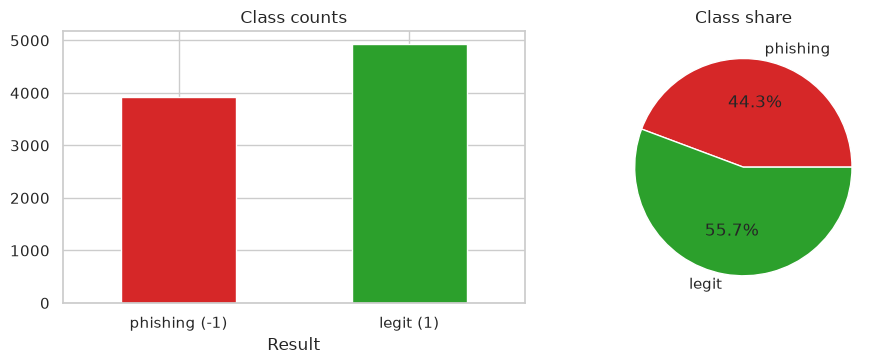

Result
-1    0.443
 1    0.557
Name: count, dtype: float64


In [5]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
counts.rename({-1: "phishing (-1)", 1: "legit (1)"}).plot(kind="bar", ax=ax[0], color=["tab:red", "tab:green"])
ax[0].set_title("Class counts"); ax[0].tick_params(axis="x", rotation=0)
ax[1].pie(counts, labels=["phishing", "legit"], autopct="%.1f%%", colors=["tab:red", "tab:green"])
ax[1].set_title("Class share"); plt.tight_layout(); plt.show()
print((counts / len(df)).round(4))

> **Reading the output:** Classes are 44.3% phishing vs 55.7% legit, a mild imbalance. No resampling is needed, and accuracy is still fair here. We track recall and F1 as well since missing phishing is the costly error.

## 4. Feature value distributions
Share of rows for each value (`-1`, `0`, `1`) per feature.

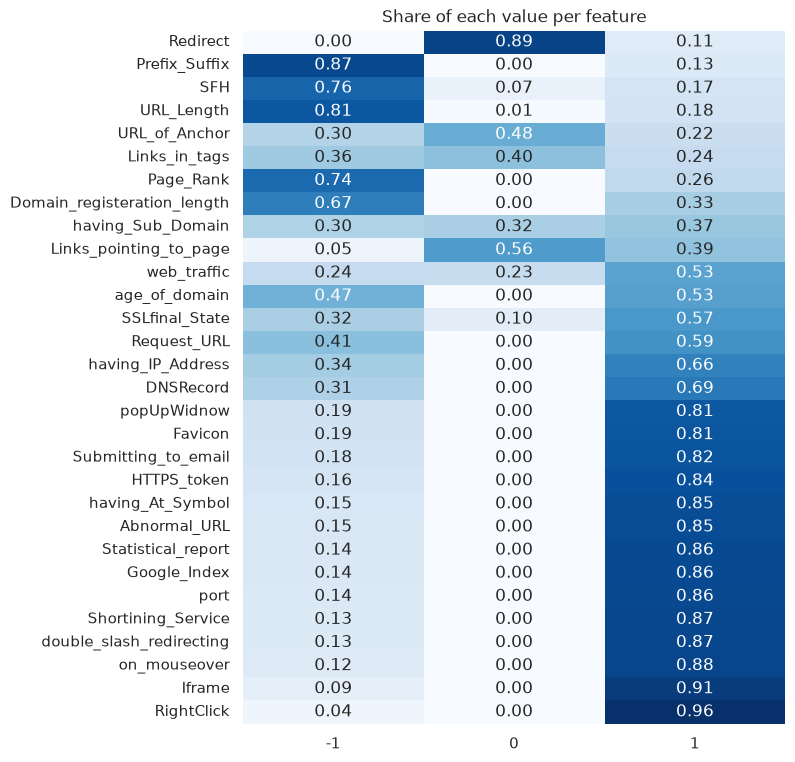

In [6]:
dist = pd.DataFrame({c: df[c].value_counts(normalize=True) for c in features}).T.fillna(0)
dist = dist.reindex(columns=[-1, 0, 1]).sort_values(1)
plt.figure(figsize=(7, 9))
sns.heatmap(dist, annot=True, fmt=".2f", cmap="Blues", cbar=False)
plt.title("Share of each value per feature"); plt.show()

> **Reading the output:** Many features are dominated by one value (rows near 0.8-0.9 in one column), while `SSLfinal_State`, `URL_of_Anchor` and `having_Sub_Domain` are spread over all three. Well-spread features usually have more room to separate the classes.

In [7]:
dominant = dist.max(axis=1).sort_values(ascending=False)
print("features where one value covers > 90% of rows:")
print(dominant[dominant > 0.90].round(3))

features where one value covers > 90% of rows:
RightClick    0.956
Iframe        0.908
dtype: float64


> **Reading the output:** Only `RightClick` (95.6%) and `Iframe` (90.8%) are almost constant. They hold little signal on their own, so they are candidates to drop, which later steps test with CV instead of assuming.

## 5. Feature vs target
Phishing rate for every feature value. Big differences between `-1`, `0`, `1` mean a useful feature.

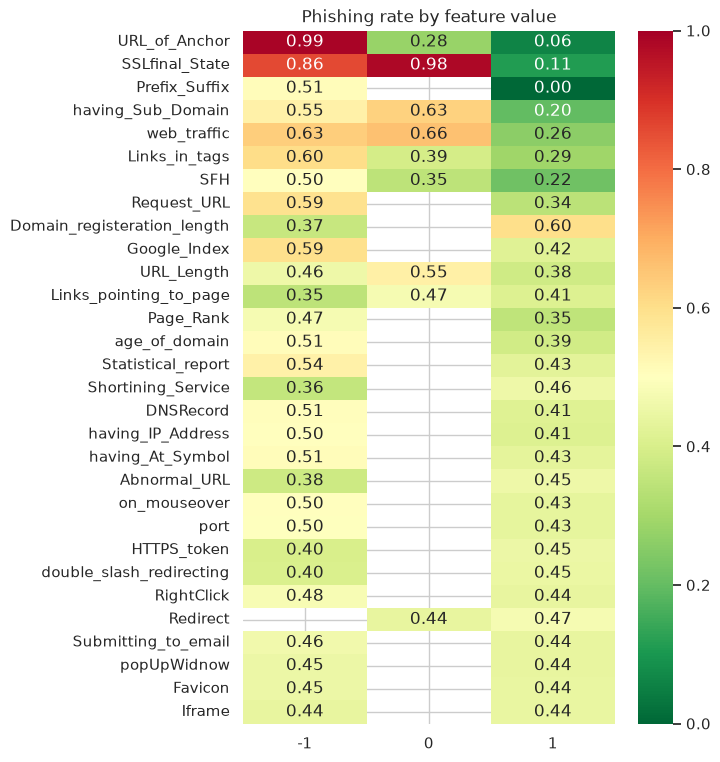

,-1,0,1,gap
URL_of_Anchor,0.989,0.279,0.061,0.928
SSLfinal_State,0.856,0.984,0.110,0.874
Prefix_Suffix,0.511,NaN,0.000,0.511
having_Sub_Domain,0.547,0.627,0.199,0.428
web_traffic,0.633,0.663,0.260,0.402
Links_in_tags,0.602,0.393,0.290,0.311
SFH,0.502,0.346,0.218,0.284
Request_URL,0.593,NaN,0.340,0.253


In [8]:
phish = (df[TARGET] == -1).astype(int)
rate = pd.DataFrame({c: phish.groupby(df[c]).mean() for c in features}).T.reindex(columns=[-1, 0, 1])
rate["gap"] = rate.max(axis=1) - rate.min(axis=1)
rate = rate.sort_values("gap", ascending=False)
plt.figure(figsize=(6, 9))
sns.heatmap(rate.drop(columns="gap"), annot=True, fmt=".2f", cmap="RdYlGn_r", vmin=0, vmax=1)
plt.title("Phishing rate by feature value"); plt.show()
rate.head(8).round(3)

> **Reading the output:** `URL_of_Anchor` = -1 is phishing 98.9% of the time, and `SSLfinal_State` = 0 is phishing 98.4% of the time. `Prefix_Suffix` = 1 is never phishing (0.0%). These very different rates per value are what a model will exploit.

## 6. Statistical tests
**Chi-square / Cramer's V** measures the strength of a feature-target link (0 = none, 1 = perfect). **Mutual information** captures any dependency.

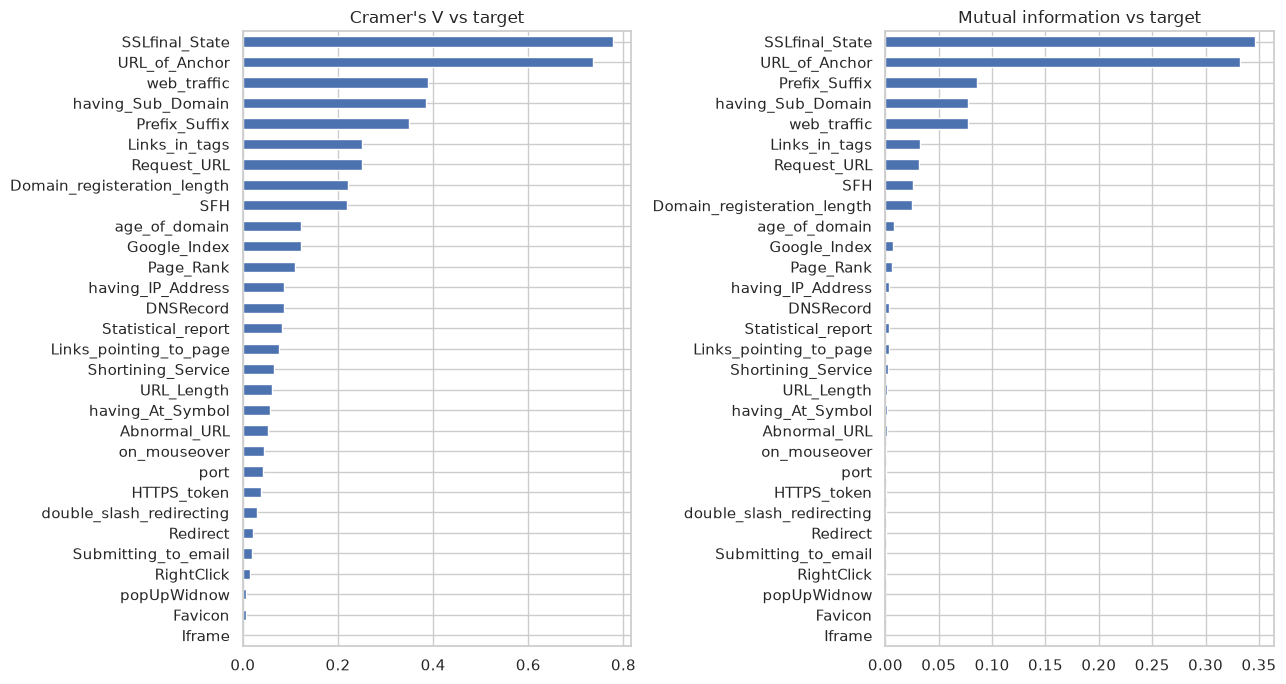

features NOT significant at p<0.05: ['Submitting_to_email', 'RightClick', 'popUpWidnow', 'Favicon', 'Iframe']


,cramers_v,p_value,mutual_info
SSLfinal_State,0.7779,0.0,0.3467
URL_of_Anchor,0.7367,0.0,0.3326
web_traffic,0.3897,0.0,0.0778
having_Sub_Domain,0.3844,0.0,0.0779
Prefix_Suffix,0.3482,0.0,0.0855
Links_in_tags,0.2514,0.0,0.0320
Request_URL,0.2497,0.0,0.0314
Domain_registeration_length,0.2210,0.0,0.0245


In [9]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(table)
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1))), p

stats = pd.DataFrame({c: cramers_v(df[c], df[TARGET]) for c in features}, index=["cramers_v", "p_value"]).T
stats["mutual_info"] = mutual_info_classif(df[features], df[TARGET], discrete_features=True, random_state=42)
stats = stats.sort_values("cramers_v", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 7))
stats["cramers_v"].sort_values().plot(kind="barh", ax=ax[0], title="Cramer's V vs target")
stats["mutual_info"].sort_values().plot(kind="barh", ax=ax[1], title="Mutual information vs target")
plt.tight_layout(); plt.show()
print("features NOT significant at p<0.05:", stats.index[stats.p_value > 0.05].tolist())
stats.head(8).round(4)

> **Reading the output:** `SSLfinal_State` (Cramer's V 0.78) and `URL_of_Anchor` (0.74) are far ahead of everything else, and mutual information agrees. Five features (`Submitting_to_email`, `RightClick`, `popUpWidnow`, `Favicon`, `Iframe`) show no significant link to the target (p > 0.05).

## 7. Correlation with the target (linear view)

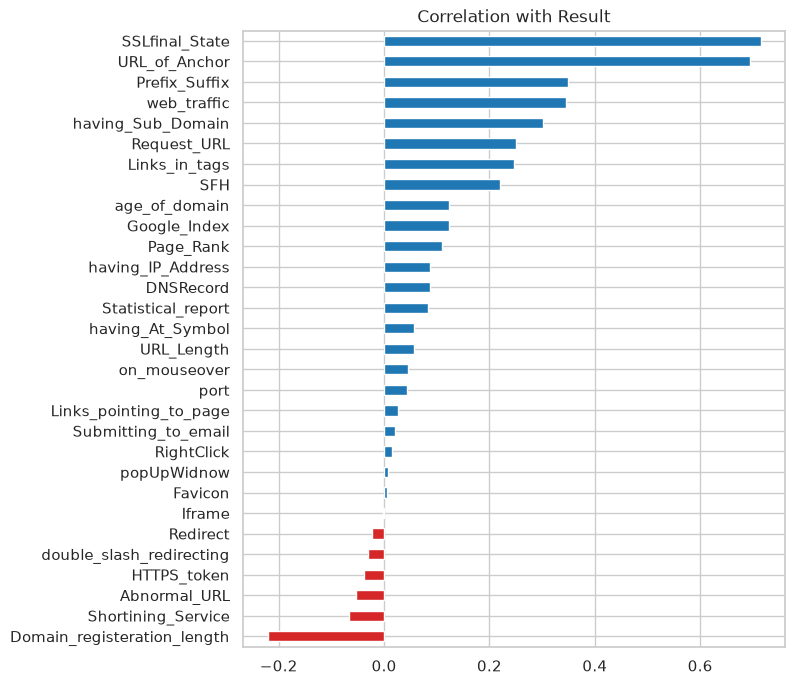

In [10]:
corr_target = df.corr()[TARGET].drop(TARGET).sort_values()
colors = ["tab:red" if v < 0 else "tab:blue" for v in corr_target]
corr_target.plot(kind="barh", figsize=(7, 8), color=colors, title="Correlation with Result")
plt.show()

> **Reading the output:** `SSLfinal_State` and `URL_of_Anchor` have the strongest linear link with `Result`, and the sign shows direction. Because these codes are categorical, correlation only partly captures their power (e.g. `SSLfinal_State` = 0 is a phishing signal, not a middle value).

## 8. Correlation between features
Strongly correlated features carry overlapping information.

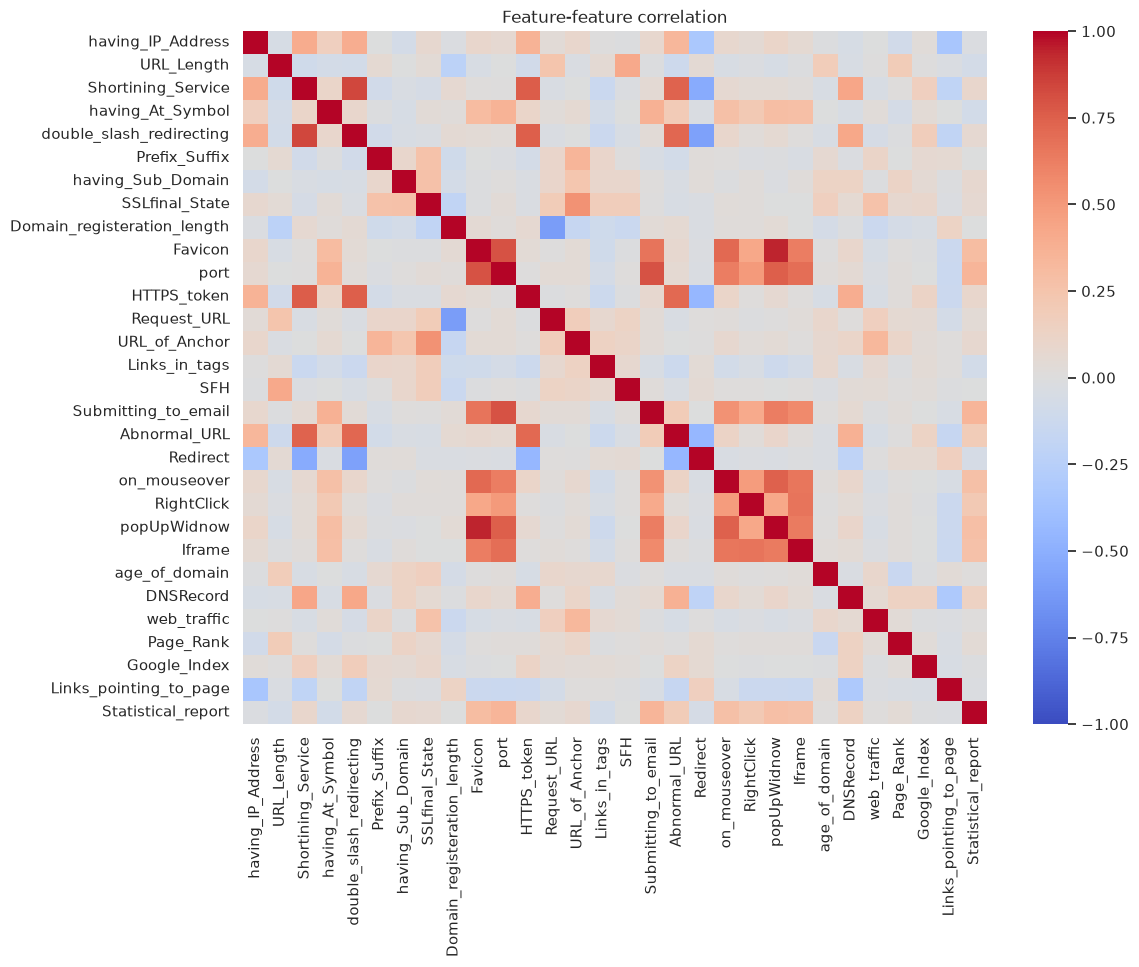

Favicon                      popUpWidnow                 0.940
Shortining_Service           double_slash_redirecting    0.837
Favicon                      port                        0.804
port                         Submitting_to_email         0.799
Shortining_Service           HTTPS_token                 0.764
double_slash_redirecting     HTTPS_token                 0.757
port                         popUpWidnow                 0.750
on_mouseover                 popUpWidnow                 0.743
Shortining_Service           Abnormal_URL                0.740
double_slash_redirecting     Abnormal_URL                0.724
HTTPS_token                  Abnormal_URL                0.717
Favicon                      on_mouseover                0.716
port                         Iframe                      0.693
RightClick                   Iframe                      0.668
Favicon                      Submitting_to_email         0.666
on_mouseover                 Iframe                    

In [11]:
corr = df[features].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Feature-feature correlation"); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("corr")
pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(3)

> **Reading the output:** A group of 'page behaviour' features (`Favicon`, `popUpWidnow`, `port`, `Iframe`, `on_mouseover`) is highly inter-correlated, topped by `Favicon`/`popUpWidnow` at 0.94. That redundancy is why we test dropping correlated features in notebook 03.

## 9. A simple engineered signal: how many red flags?
Count of suspicious (`-1`) features per site, compared across classes.

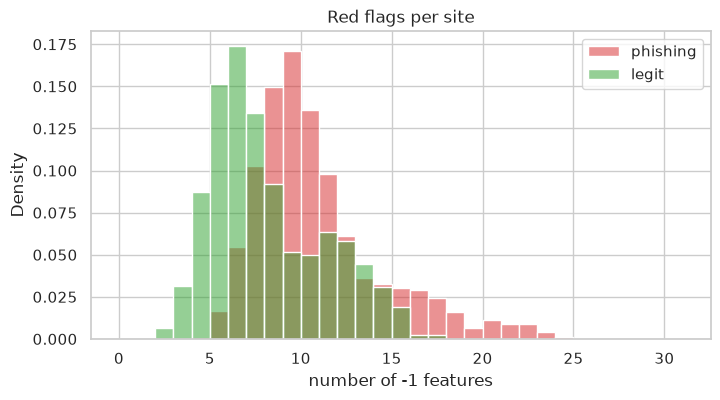

         count   mean   std  min  25%   50%   75%   max
Result                                                 
-1      3918.0  10.43  3.60  3.0  8.0  10.0  12.0  24.0
 1      4926.0   7.68  3.13  2.0  5.0   7.0  10.0  19.0


In [12]:
flags = (df[features] == -1).sum(axis=1)
plt.figure(figsize=(8, 4))
for label, name, color in [(-1, "phishing", "tab:red"), (1, "legit", "tab:green")]:
    sns.histplot(flags[df[TARGET] == label], bins=range(0, 32), stat="density", alpha=0.5, label=name, color=color)
plt.xlabel("number of -1 features"); plt.legend(); plt.title("Red flags per site"); plt.show()
print(flags.groupby(df[TARGET]).describe().round(2))

> **Reading the output:** Phishing sites average 10.4 suspicious (-1) features vs 7.7 for legit sites. The distributions overlap but are clearly shifted, so a simple 'red flag count' carries some signal, but not enough to work alone.

## 10. Is the data separable? (PCA to 2D)
Projecting 30 features to 2 components, only for a visual check.

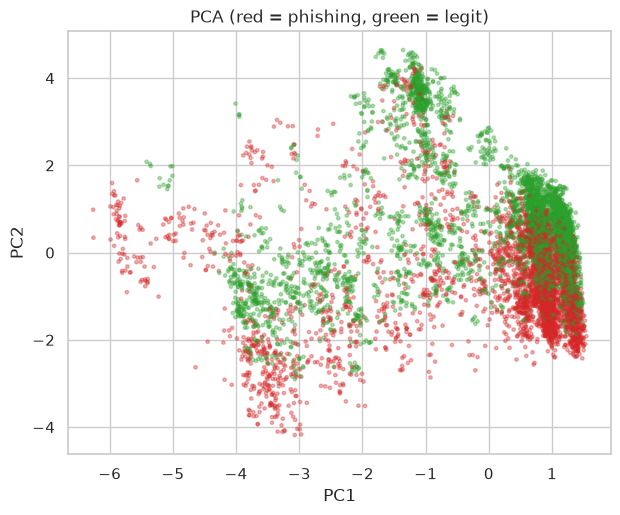

variance explained by 2 components: [0.155 0.118] = 0.273


In [13]:
pca = PCA(n_components=2, random_state=42).fit(df[features])
xy = pca.transform(df[features])
rng = np.random.RandomState(42)
jitter = rng.normal(0, 0.05, xy.shape)
plt.figure(figsize=(7, 5.5))
plt.scatter(*(xy + jitter).T, c=np.where(df[TARGET] == -1, "tab:red", "tab:green"), s=6, alpha=0.35)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA (red = phishing, green = legit)"); plt.show()
print("variance explained by 2 components:", pca.explained_variance_ratio_.round(3), "=", round(pca.explained_variance_ratio_.sum(), 3))

> **Reading the output:** Two components explain only 27% of the variance, and the classes overlap heavily in 2D. The problem is not linearly separable by a few directions, which fits tree models beating logistic regression later.

## Takeaways
- `SSLfinal_State` and `URL_of_Anchor` are by far the strongest signals (Cramer's V 0.78 / 0.74).
- Data is clean (no missing values) and fairly balanced (44% phishing). 42% of rows are duplicates, so scores have a natural ceiling.
- Five features show no significant link to the target, and a few groups are highly correlated, which makes them pruning candidates.
- The classes overlap in 2D PCA, so expect non-linear models (trees) to beat linear ones.